In [2]:
%pip install matplotlib-label-lines


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: C:\Users\Dell User\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [ ]:
%pip install tqdm

In [ ]:
%pip install xgboost 

In [ ]:
%pip install scikit-learn

In [ ]:
import os, warnings
import sys
import json
import traceback
from math import sqrt
import calendar
import pandas as pd
import numpy as np
from tqdm.auto import tqdm
from labellines import labelLine, labelLines
import xgboost
from sklearn.utils import shuffle
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_percentage_error

warnings.filterwarnings("ignore")  

In [ ]:
import matplotlib.pyplot as plt
plt.style.library["seaborn-whitegrid"] = (
    plt.style.library["seaborn-v0_8-whitegrid"]
)

In [ ]:
DATASET_NAME = 'boralasgamuwa_uc_2012-2018'
DAILY_WASTE_DATA_FILE_PATH = f'/content/{DATASET_NAME}.csv'

PREPROCESSING_CACHE_DIR_PATH = '/content/preprocessing_cache'
os.makedirs(PREPROCESSING_CACHE_DIR_PATH, exist_ok=True)

In [5]:
print("Results folder:", PREPROCESSING_CACHE_DIR_PATH)

Results folder: /content/preprocessing_cache


Import datasets.

In [6]:
df = pd.read_csv("boralasgamuwa_uc_2012-2018.csv")

In [7]:
df.head(5)

,area,ticket_date,waste_type,net_weight_kg
0,Boralesgamuwa UC,2012-01-01,MSW,17340.0
1,Boralesgamuwa UC,2012-01-02,MSW,25980.0
2,Boralesgamuwa UC,2012-01-03,MSW,29220.0
3,Boralesgamuwa UC,2012-01-04,MSW,7450.0
4,Boralesgamuwa UC,2012-01-05,MSW,10520.0


In [8]:
df.shape

(2988, 4)

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2988 entries, 0 to 2987
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   area           2988 non-null   object 
 1   ticket_date    2988 non-null   object 
 2   waste_type     2988 non-null   object 
 3   net_weight_kg  2988 non-null   float64
dtypes: float64(1), object(3)
memory usage: 93.5+ KB


In [10]:
df.describe()

,net_weight_kg
count,2988.000000
mean,22159.832664
std,12825.464915
min,0.000000
25%,12767.500000
50%,23905.000000
75%,30682.500000
max,215040.000000


Check missing data

In [11]:
print(df['net_weight_kg'].isna().sum())

0


In [12]:
print(df['ticket_date'].duplicated().sum())


571


In [13]:
df['ticket_date'] = pd.to_datetime(df['ticket_date'])

In [14]:
print("Date range:")
print(df['ticket_date'].min(), "to", df['ticket_date'].max())

Date range:
2012-01-01 00:00:00 to 2018-12-31 00:00:00


In [15]:
expected_dates = pd.date_range(
    start=df['ticket_date'].min(),
    end=df['ticket_date'].max(),
    freq='D'
)

In [16]:
missing_dates = expected_dates.difference(df['ticket_date'])

In [17]:
print("Missing dates:", len(missing_dates))
print(missing_dates)

Missing dates: 140
DatetimeIndex(['2014-10-16', '2014-10-17', '2014-10-18', '2014-10-19',
               '2014-10-20', '2014-10-21', '2014-10-22', '2014-10-23',
               '2014-10-24', '2014-10-25',
               ...
               '2018-03-27', '2018-04-01', '2018-05-01', '2018-06-01',
               '2018-07-01', '2018-08-01', '2018-09-01', '2018-12-01',
               '2018-12-13', '2018-12-14'],
              dtype='datetime64[ns]', length=140, freq=None)


In [18]:
zero_count = (df['net_weight_kg'] == 0).sum()

print("Number of zero values:", zero_count)
print("Percentage of zero values:",
      zero_count / len(df) * 100, "%")

Number of zero values: 5
Percentage of zero values: 0.16733601070950468 %


checking outliers

In [19]:
Q1 = df['net_weight_kg'].quantile(0.25)
Q3 = df['net_weight_kg'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[
    (df['net_weight_kg'] < lower_limit) |
    (df['net_weight_kg'] > upper_limit)
]

print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)
print("Number of potential outliers:", len(outliers))

print(outliers[['ticket_date', 'net_weight_kg']])

Lower limit: -14105.0
Upper limit: 57555.0
Number of potential outliers: 5
     ticket_date  net_weight_kg
1088  2015-01-09        89580.0
1298  2015-08-13       159020.0
1304  2015-08-19        87670.0
1383  2015-11-08       215040.0
1413  2015-12-08       166680.0


In [20]:
daily_df = (
    df.groupby('ticket_date', as_index=False)['net_weight_kg']
    .sum()
)

daily_df['day_of_week'] = daily_df['ticket_date'].dt.day_name()
daily_df['month'] = daily_df['ticket_date'].dt.month
daily_df['year'] = daily_df['ticket_date'].dt.year

In [21]:
#Average waste by day of the week
weekday_avg = daily_df.groupby(
    'day_of_week'
)['net_weight_kg'].mean()

print(weekday_avg)

day_of_week
Friday       28871.511628
Monday       27601.896552
Saturday     25806.820809
Sunday       19858.057971
Thursday     29762.238372
Tuesday      29849.478261
Wednesday    30028.550725
Name: net_weight_kg, dtype: float64


In [22]:
#average waste by month
monthly_avg = daily_df.groupby(
    'month'
)['net_weight_kg'].mean()

print(monthly_avg)

month
1     25164.285714
2     25942.717949
3     26773.981043
4     25535.609756
5     27530.512821
6     28682.139037
7     27221.030928
8     27585.507246
9     26964.466019
10    28521.370558
11    28909.708738
12    29907.156398
Name: net_weight_kg, dtype: float64


Find the categories under waste_type.

In [23]:
waste_type_list = list(df['waste_type'].unique())

### Preprocess datasets.

In [24]:
# Get the year.
df['year'] = pd.DatetimeIndex(df['ticket_date']).year

In [25]:
# Get the month.
df['month'] = pd.DatetimeIndex(df['ticket_date']).month

In [26]:
df.columns

Index(['area', 'ticket_date', 'waste_type', 'net_weight_kg', 'year', 'month'], dtype='object')

### Filter the `ticket_date` and `net_weight_kg` columns.

In [27]:
df = df[['ticket_date', 'net_weight_kg']].groupby(['ticket_date']).agg('sum').reset_index()

### Convert `ticket_date` to UTC.

In [28]:
df['ticket_date'] = pd.to_datetime(df['ticket_date'], utc=True)

### Get dates between 2012-01-01 and 2018-12-31.

In [29]:
date_range_df = pd.date_range(start="2012-01-01", end="2018-12-31").to_frame(index=False, name='ticket_date')
date_range_df['ticket_date'] = pd.to_datetime(date_range_df['ticket_date'], utc=True)

### Add the complete date range to the df.

In [30]:
df = pd.merge(left=date_range_df, right=df, how='left', left_on='ticket_date', right_on='ticket_date')

### Convert `net_waste_kg` to numeric.

In [31]:
df['net_weight_kg'] = pd.to_numeric(df['net_weight_kg'])

### Available values

In [32]:
print(f'Available values: {df["net_weight_kg"].count()}')

Available values: 2417


### Missing values in net_weight_kg

In [33]:
missing_value_count = df["net_weight_kg"].isna().sum()
print(f'# missing values: {missing_value_count}')

# missing values: 140


In [34]:
df.isnull().sum()

,0
ticket_date,0
net_weight_kg,140


In [35]:
# df['net_weight_kg'] = df['net_weight_kg'].interpolate(method='linear', limit_direction='both')
df = df.fillna(-50000)

In [36]:
df.isnull().sum()

,0
ticket_date,0
net_weight_kg,0


In [37]:
df = df.set_index('ticket_date')

In [38]:
%pip install adtk

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 2.3 MB/s eta 0:00:00


In [39]:
from adtk.data import validate_series
df = validate_series(df)
display(df)

,net_weight_kg
ticket_date,
2012-01-01 00:00:00+00:00,17340.0
2012-01-02 00:00:00+00:00,25980.0
2012-01-03 00:00:00+00:00,29220.0
2012-01-04 00:00:00+00:00,7450.0
2012-01-05 00:00:00+00:00,10520.0
...,...
2018-12-27 00:00:00+00:00,31090.0
2018-12-28 00:00:00+00:00,29980.0
2018-12-29 00:00:00+00:00,26380.0


[<Axes: >]

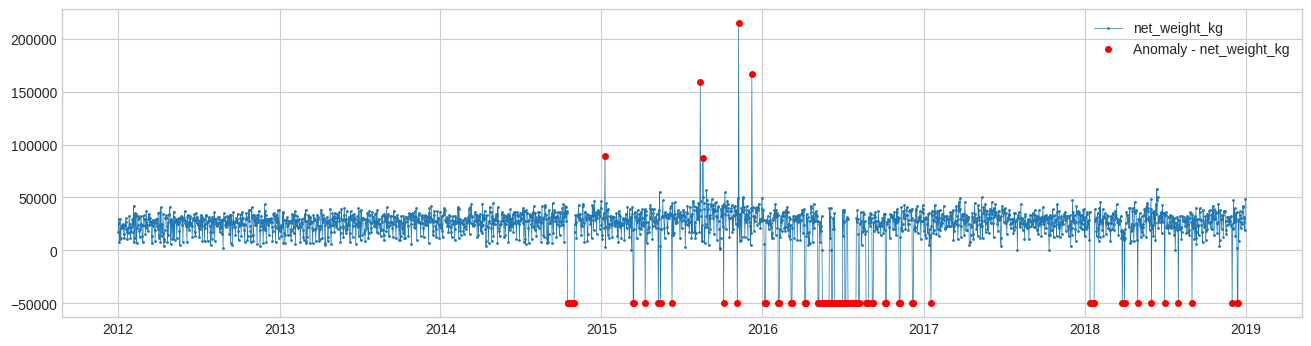

In [40]:
from adtk.detector import SeasonalAD
from adtk.visualization import plot

# Create the seasonal anomaly detector
seasonal_ad = SeasonalAD()

# Detect anomalies in the time-series data
anomalies = seasonal_ad.fit_detect(df)

# Plot the original data and highlight anomalies
plot(
    df,
    anomaly=anomalies,
    anomaly_color="red",
    anomaly_tag="marker"
)

Remove outliers

In [41]:
anomalies_mask = np.array(anomalies.reset_index()['net_weight_kg'].tolist())

In [42]:
print(f'outliers: {anomalies_mask.sum() - missing_value_count}')

#original - 29

outliers: 5


In [43]:
df['net_weight_kg'] = df['net_weight_kg'].iloc[~anomalies_mask]

In [44]:
df = df.reset_index()

### Waste Data Visualization

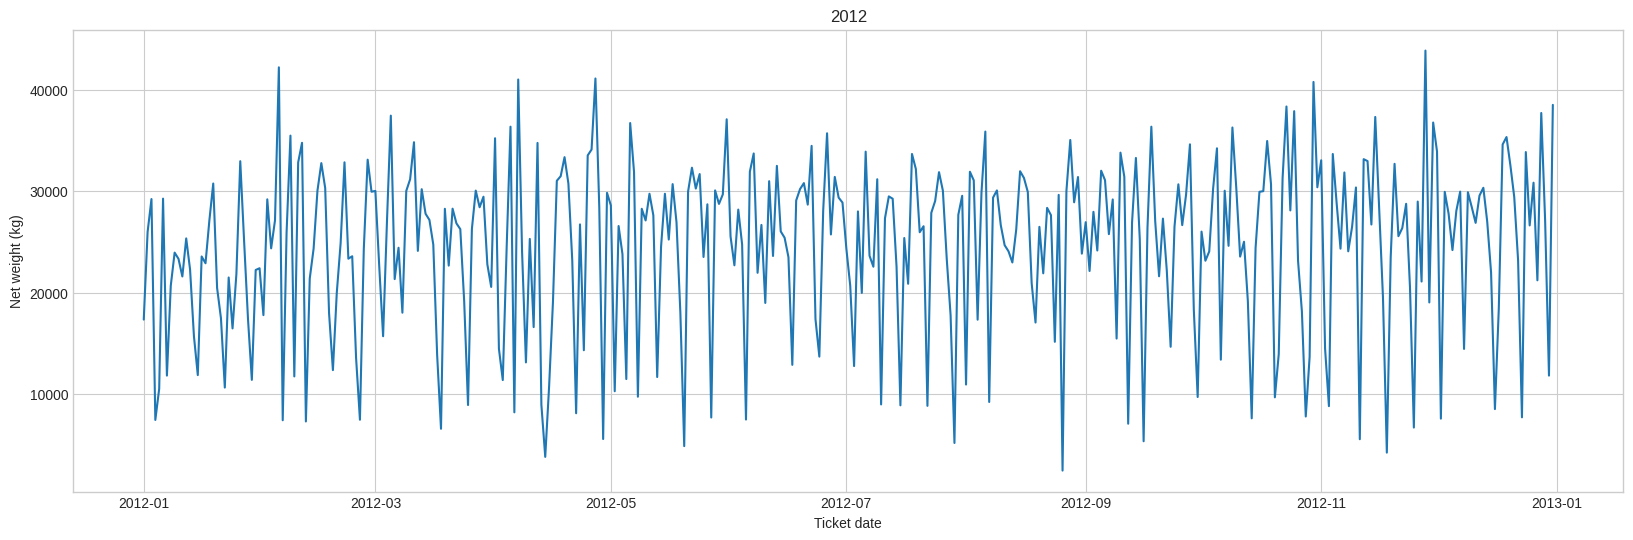

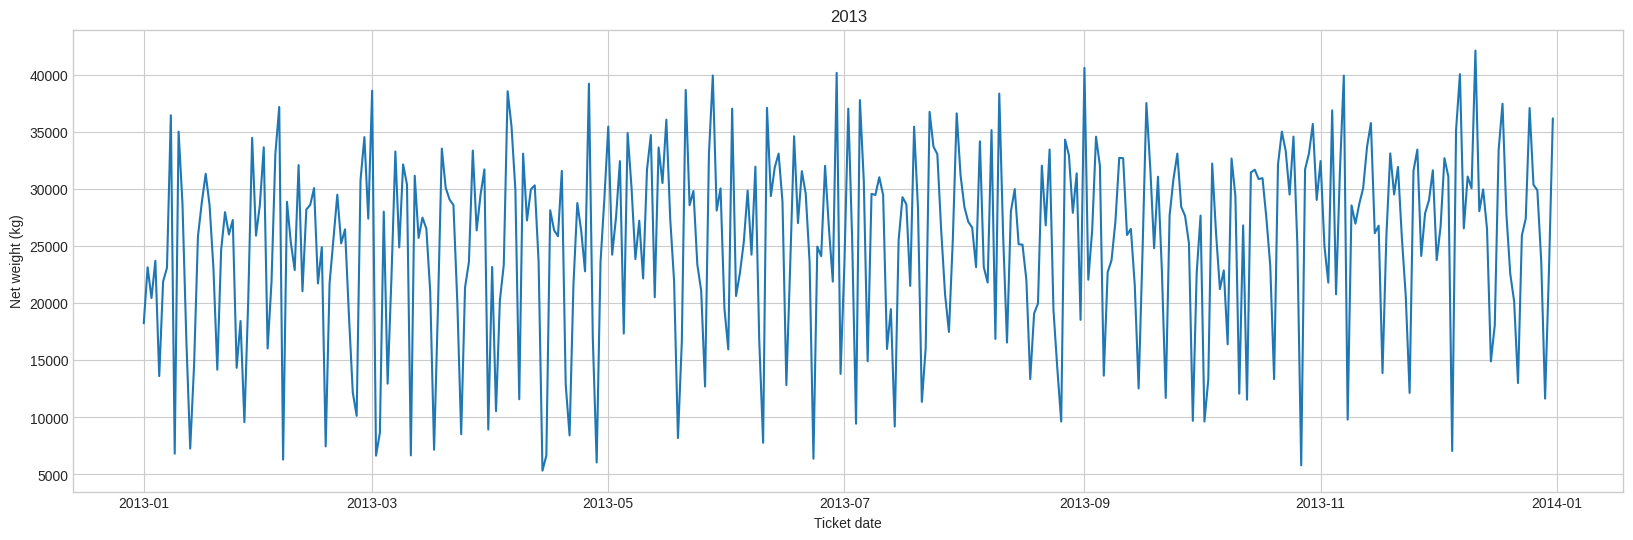

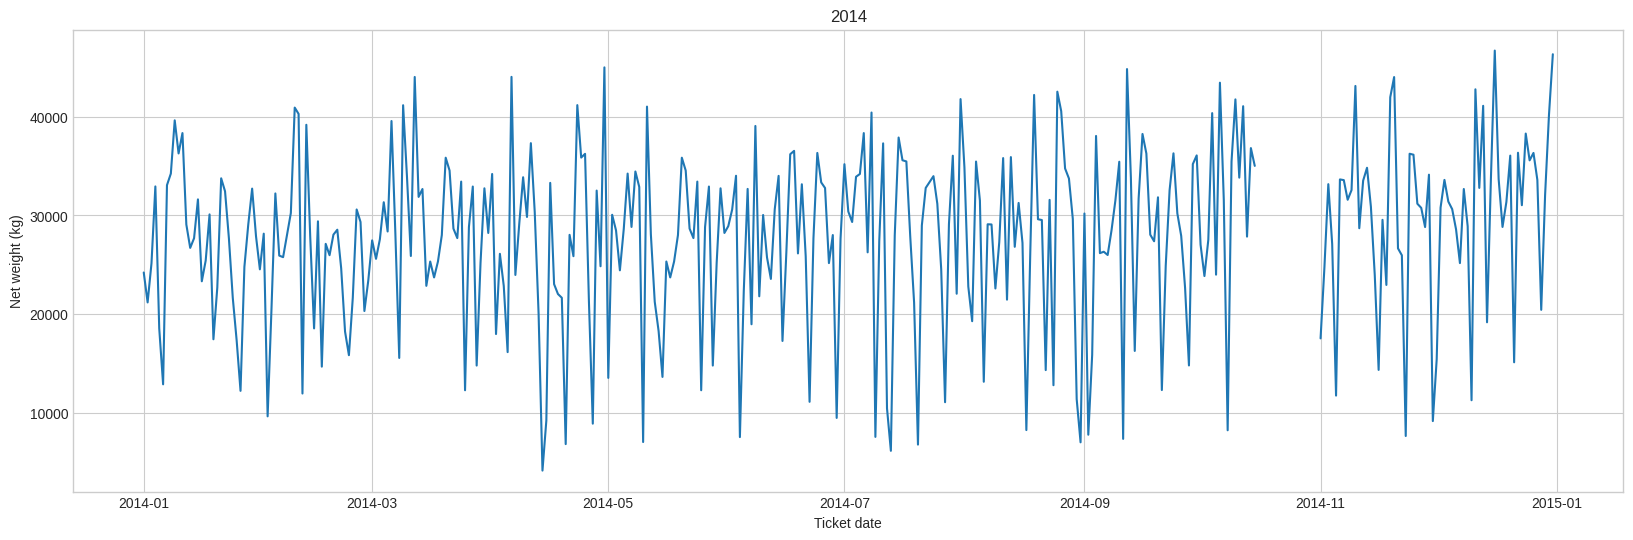

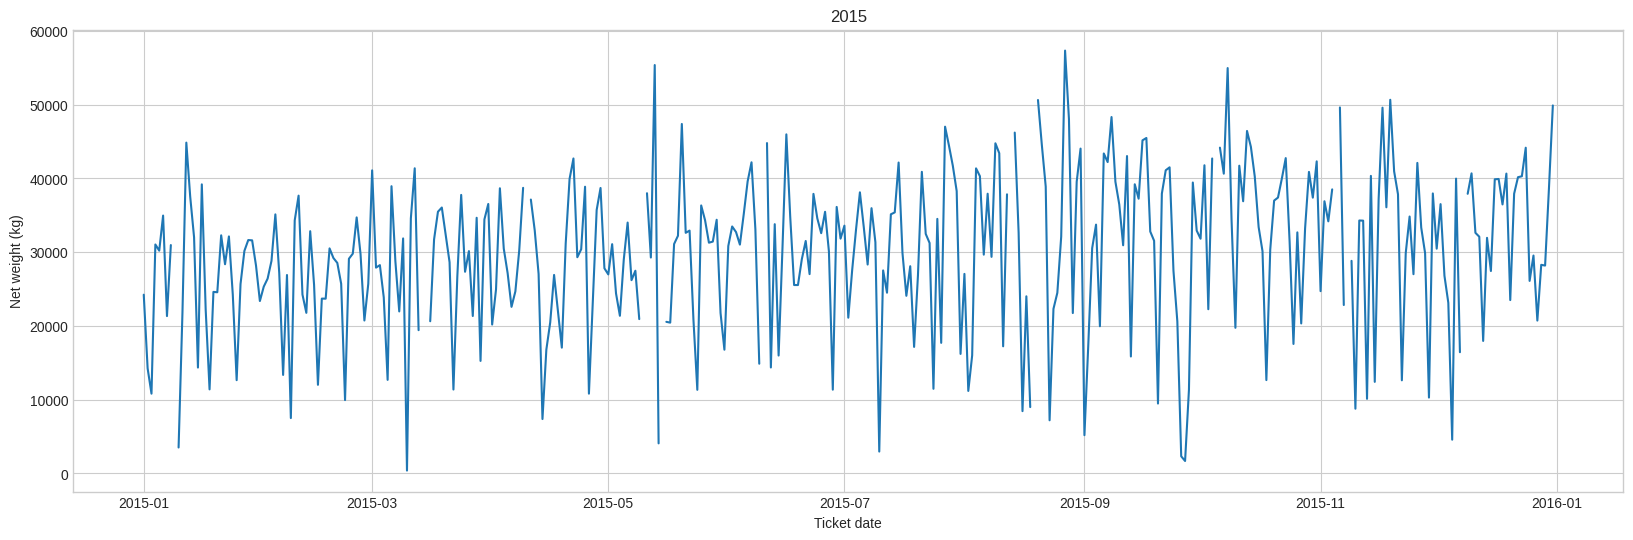

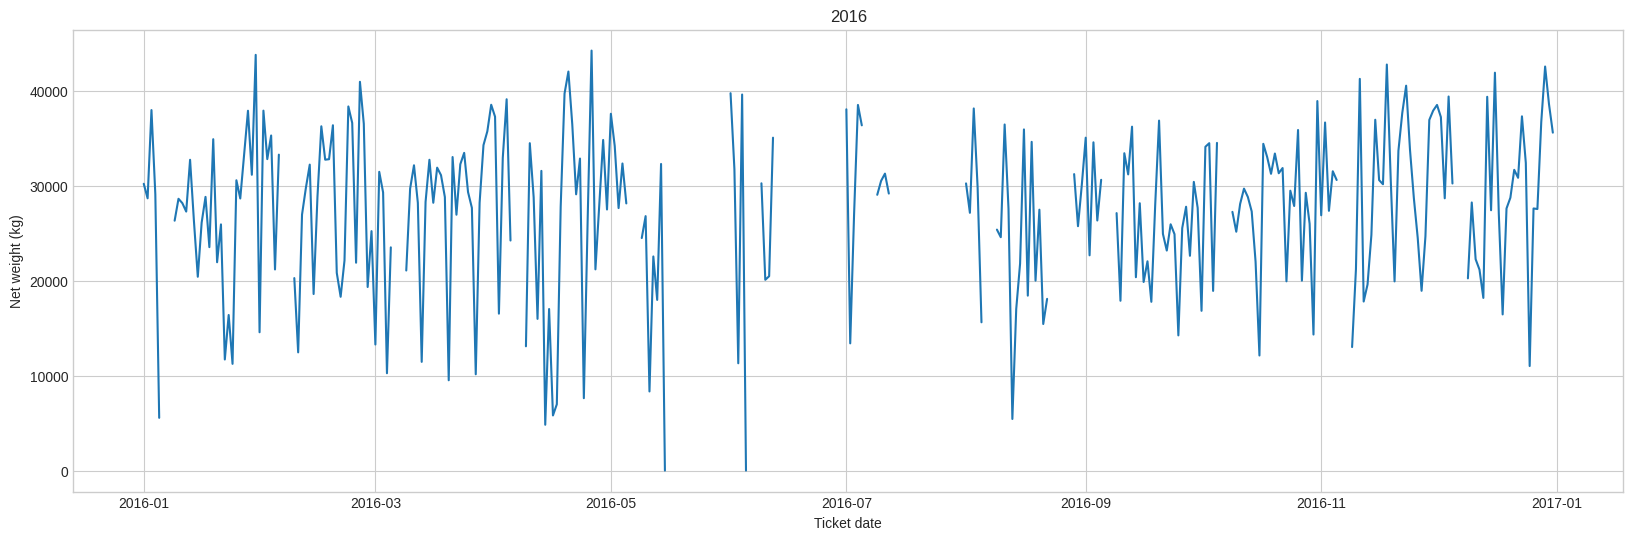

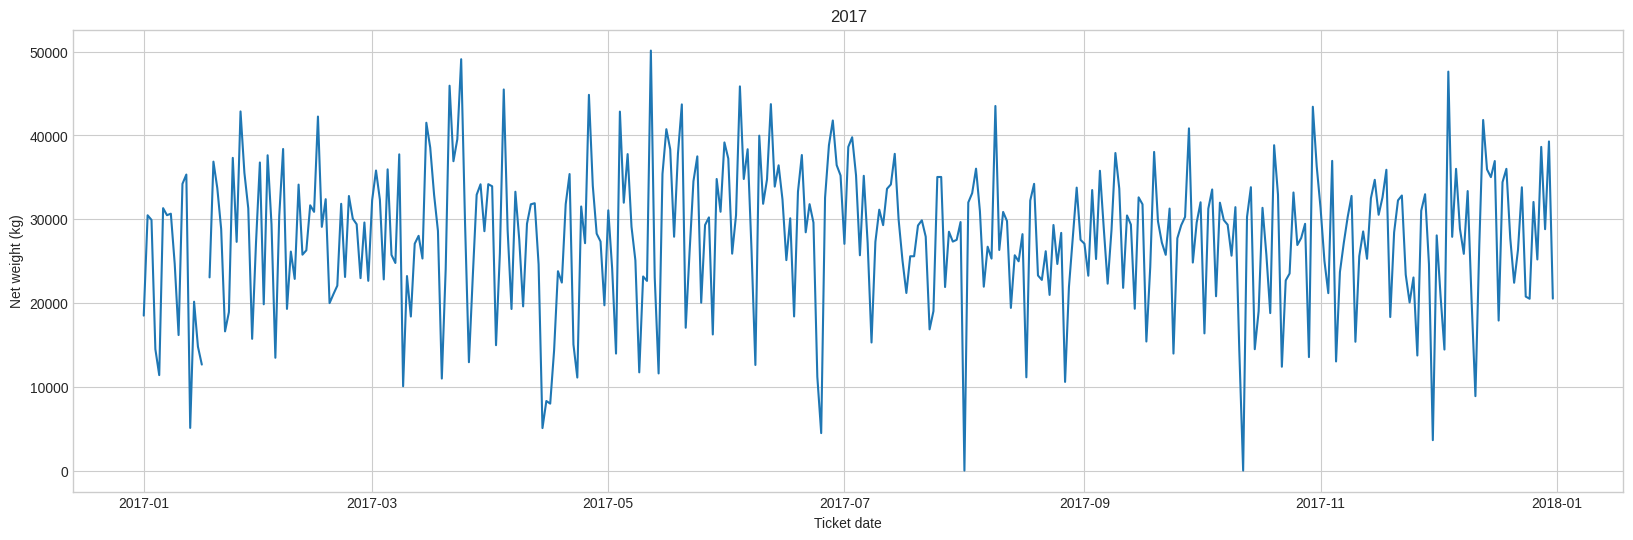

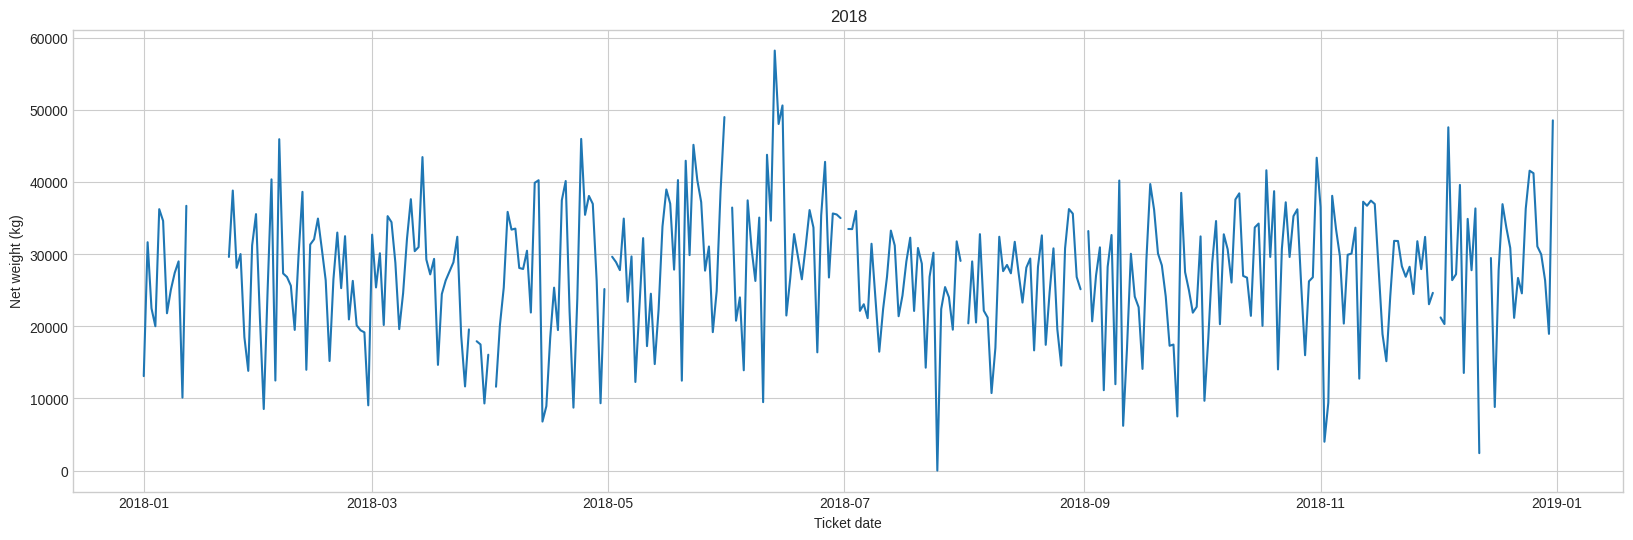

In [45]:
for year in range(2012, 2019):
    x = df[df['ticket_date'].dt.year == year]['ticket_date'].tolist()
    y = df[df['ticket_date'].dt.year == year]['net_weight_kg'].tolist()

    plt.rcParams['figure.dpi'] = 100
    plt.rcParams["figure.figsize"] = (20, 6)

    plt.plot(x, y)
    plt.title('{}'.format(year))
    plt.xlabel('Ticket date')
    plt.ylabel('Net weight (kg)')
    plt.show()

### best model selection

Hyperparameter tuning for XGBoost

In [ ]:
lag_count_list = [42, 360, 150, 120, 49, 14, 90]
estimator_count_list = [10, 100, 1000]
max_depth_list = [7, 3, 8 , 9, 4, 6]
subsample_list = [0.6, 0.9, 0.7, 0.8]
eta_list = [0.01, 0.3, 0.1]

n_iter = (len(lag_count_list) * len(estimator_count_list) * len(max_depth_list)
          * len(subsample_list) * len(eta_list))
print("Total configurations:", n_iter)

In [ ]:
def evaluate(lag_count, estimator_count, max_depth, subsample, eta):

    # uses the complete series (as in the authors' pipeline)
    df_temp = df.copy()

    for i in range(1, lag_count + 1):
        df_temp[f'net_weight_kg_lag_{i}'] = df_temp['net_weight_kg'].shift(i)

    lag_columns = [f'net_weight_kg_lag_{i}' for i in range(1, lag_count + 1)]
    df_temp = df_temp.dropna(subset=['net_weight_kg'] + lag_columns)

    X = df_temp.drop(columns=['ticket_date', 'net_weight_kg'])
    y = df_temp['net_weight_kg']

    split_index = int(len(df_temp) * 0.8)            # time order: first 80% train, last 20% test
    X_train, X_test = X.iloc[:split_index], X.iloc[split_index:]
    y_train, y_test = y.iloc[:split_index], y.iloc[split_index:]

    model = xgboost.XGBRegressor(
        n_estimators=estimator_count, random_state=0, max_depth=max_depth,
        subsample=subsample, learning_rate=eta,
        objective='reg:squarederror', n_jobs=-1)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    return sqrt(mean_squared_error(y_test, y_pred))

In [ ]:
# complete series is used, so keep a folder name that says so (never reuse a folder from another dataset or split)
DATASET_NAME = "Moratuwa"
PREPROCESSING_CACHE_DIR_PATH = f'../preprocessing_cache_{DATASET_NAME}_full'
os.makedirs(PREPROCESSING_CACHE_DIR_PATH, exist_ok=True)
os.makedirs("../grid_search_results", exist_ok=True)

results, errors = [], []

with tqdm(total=n_iter, desc="Grid Search") as pbar:
    for lag_count in lag_count_list:
        for estimator_count in estimator_count_list:
            for max_depth in max_depth_list:
                for subsample in subsample_list:
                    for eta in eta_list:
                        filename = (f'lag-{lag_count}_est-{estimator_count}_dpt-{max_depth}'
                                    f'_subsmp-{subsample}_eta-{eta}.json')
                        file_path = os.path.join(PREPROCESSING_CACHE_DIR_PATH, filename)
                        try:
                            if os.path.exists(file_path):
                                with open(file_path, 'r') as f:
                                    summary = json.load(f)
                            else:
                                rmse = evaluate(lag_count, estimator_count, max_depth, subsample, eta)
                                summary = {'rmse': float(rmse), 'lag_count': lag_count,
                                           'estimator_count': estimator_count, 'max_depth': max_depth,
                                           'subsample': subsample, 'eta': eta}
                                with open(file_path, 'w') as f:
                                    json.dump(summary, f, indent=4)
                            results.append(summary)
                        except Exception as e:
                            errors.append({'filename': filename, 'error': str(e)})
                        finally:
                            pbar.update(1)

print("Successful results:", len(results), "| Failed:", len(errors))
if errors: print(errors[:3])

results_df = pd.DataFrame(results).sort_values('rmse').reset_index(drop=True)
display(results_df)
results_df.to_csv("../grid_search_results/all_grid_search_results_Boralasgamuwa.csv", index=False)    # CHANGED: local path

#### all results

In [ ]:
results_df = pd.DataFrame(results).sort_values('rmse').reset_index(drop=True)
print("Top 10 settings")
display(results_df.head(10))

#### best setting for each lag count

In [ ]:
best_per_lag = results_df.loc[results_df.groupby('lag_count')['rmse'].idxmin()].sort_values('rmse')
print("Best setting for each lag count")
display(best_per_lag)

def to_params(row):
    return {'rmse': float(row['rmse']), 'lag_count': int(row['lag_count']),
            'estimator_count': int(row['estimator_count']), 'max_depth': int(row['max_depth']),
            'subsample': float(row['subsample']), 'eta': float(row['eta'])}

#### optimum-lag model = the lowest RMSE of all settings

In [ ]:
optimum_lag_model_params = to_params(best_per_lag.iloc[0])

#### minimum-lag model = the lowest RMSE among lag counts that fit before the first blank day

In [ ]:
null_rows = df.index[df['net_weight_kg'].isna()]
first_null_index = int(null_rows[0]) if len(null_rows) > 0 else len(df)
print("First blank row index:", first_null_index)

short_ok = best_per_lag[best_per_lag['lag_count'] < first_null_index]
if len(short_ok) == 0:
    raise ValueError(f"No lag count below {first_null_index} was tested. "
                     "Add a smaller lag (for example 7 or 14) to lag_count_list and run the search again.")
minimum_lag_model_params = to_params(short_ok.iloc[0])

print("\nOptimum lag model:", optimum_lag_model_params)
print("Minimum lag model:", minimum_lag_model_params)

In [ ]:
def evaluate_forecast(actual, predicted, plot_title=None):
    rmse = sqrt(mean_squared_error(actual, predicted))
    mae = mean_absolute_error(actual, predicted)
    try:
        mape = mean_absolute_percentage_error(actual, predicted)
    except Exception:
        mape = None
    print('RMSE:', rmse, '| MAE:', mae, '| MAPE:', mape)

    plt.figure(figsize=(20, 6), dpi=100)
    plt.plot(np.asarray(actual))
    plt.plot(np.asarray(predicted))
    if plot_title:                                  
        plt.title(plot_title)
    plt.show()
    return rmse, mae, mape

In [ ]:
df_temp = df.copy()                                          

for i in range(1, optimum_lag_model_params['lag_count'] + 1):
    df_temp['net_weight_kg_lag_{}'.format(i)] = df_temp['net_weight_kg'].shift(i)
df_temp = df_temp.dropna()
del df_temp['ticket_date']

X = df_temp.drop(['net_weight_kg'], axis=1)
y = df_temp['net_weight_kg'].tolist()

cut = int(len(X) * 0.8)
X_train, X_test = X.iloc[:cut], X.iloc[cut:]
y_train, y_test = y[:cut], y[cut:]

model_optimum = xgboost.XGBRegressor(
    n_estimators=optimum_lag_model_params['estimator_count'],
    seed=0,
    max_depth=optimum_lag_model_params['max_depth'],
    subsample=optimum_lag_model_params['subsample'],
    eta=optimum_lag_model_params['eta'])
model_optimum.fit(X_train, y_train)
y_pred = model_optimum.predict(X_test)

evaluate_forecast(y_test, y_pred, "Optimum lag model")

# CHANGED: baseline = same weekday last week (needs a lag count of at least 7)
if "net_weight_kg_lag_7" in X_test.columns:
    base = X_test["net_weight_kg_lag_7"].to_numpy()
    print("Baseline RMSE (same weekday last week):", sqrt(mean_squared_error(y_test, base)))
else:
    print("Baseline skipped: this model uses fewer than 7 lags.")

In [ ]:
df_temp = df.copy()                                          

for i in range(1, minimum_lag_model_params['lag_count'] + 1):
    df_temp['net_weight_kg_lag_{}'.format(i)] = df_temp['net_weight_kg'].shift(i)
df_temp = df_temp.dropna()
del df_temp['ticket_date']

X = df_temp.drop(['net_weight_kg'], axis=1)
y = df_temp['net_weight_kg'].tolist()

cut = int(len(X) * 0.8)                                      
X_train, X_test = X.iloc[:cut], X.iloc[cut:]
y_train, y_test = y[:cut], y[cut:]

model_minimum = xgboost.XGBRegressor(
    n_estimators=minimum_lag_model_params['estimator_count'],
    seed=0,
    max_depth=minimum_lag_model_params['max_depth'],
    subsample=minimum_lag_model_params['subsample'],
    eta=minimum_lag_model_params['eta'])
model_minimum.fit(X_train, y_train)
y_pred = model_minimum.predict(X_test)

evaluate_forecast(y_test, y_pred, "Minimum lag model")

# baseline = same weekday last week (needs a lag count of at least 7)
if "net_weight_kg_lag_7" in X_test.columns:
    base = X_test["net_weight_kg_lag_7"].to_numpy()
    print("Baseline RMSE (same weekday last week):", sqrt(mean_squared_error(y_test, base)))
else:
    print("Baseline skipped: this model uses fewer than 7 lags.")

In [ ]:
df['predicted_net_weight_kg'] = np.nan

for index in df.index:
    if pd.isnull(df.at[index, 'net_weight_kg']):

        if index > optimum_lag_model_params['lag_count']:
            lag = optimum_lag_model_params['lag_count']
            model = model_optimum
        else:
            lag = minimum_lag_model_params['lag_count']
            model = model_minimum

        previous_values = df['net_weight_kg'].iloc[index - lag:index].tolist()[::-1]
        column_list = ['net_weight_kg_lag_{}'.format(i) for i in range(1, lag + 1)]
        previous_df = pd.DataFrame([previous_values], columns=column_list)

        value = float(max(model.predict(previous_df)[0], 0.0))  
        df.at[index, 'net_weight_kg'] = value
        df.at[index, 'predicted_net_weight_kg'] = value

In [ ]:
n_imputed = int(df["predicted_net_weight_kg"].count())
print(f"Imputed values: {n_imputed}")
print(f"Percentage of imputed values: {n_imputed / len(df) * 100:.2f} %")  
print(f"Mean of imputed values: {df['predicted_net_weight_kg'].mean()}")
print(f"SD of imputed values: {df['predicted_net_weight_kg'].std()}")
print("Blanks left:", df['net_weight_kg'].isna().sum())                    

In [ ]:
plt.figure(figsize=(20, 6))
plt.plot(df['ticket_date'], df['net_weight_kg'], label='Actual / stored values', linewidth=1)
plt.plot(df['ticket_date'], df['predicted_net_weight_kg'], color='red', label='Predicted values', linewidth=1)
plt.title('Actual and Predicted Daily Waste Weight')
plt.xlabel('Ticket date'); plt.ylabel('Net weight (kg)')
plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

for year in range(2001, 2012):
    df_year = df[df['ticket_date'].dt.year == year]
    plt.figure(figsize=(20, 6), dpi=100)
    plt.plot(df_year['ticket_date'], df_year['net_weight_kg'], label='Actual', linewidth=1)
    plt.plot(df_year['ticket_date'], df_year['predicted_net_weight_kg'], color='red', label='Predicted', linewidth=1)
    plt.title(f'Actual vs Predicted Daily Waste Weight - {year}')
    plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

In [ ]:
df_backup = df.copy()

In [ ]:
del df['predicted_net_weight_kg']

In [ ]:
df.columns

In [ ]:
df.to_csv("../processed_datasets/daily_waste_output_Boralasgamuwa.csv", index=False)
print("File saved: daily_waste_output_Boralasgamuwa.csv")